In [1]:
from google.cloud import bigquery
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ID = "steam-recommender-514518"
DATASET_ID = "steam_data"
TABLE_NAME = "interactions_clean"

table_id = f"{PROJECT_ID}.{DATASET_ID}.{TABLE_NAME}"

client = bigquery.Client(project=PROJECT_ID)

In [2]:
query = f"""
    SELECT
        COUNT(*) AS total_interactions,
        COUNT(DISTINCT user_id) AS unique_users,
        COUNT(DISTINCT game_id) AS unique_games,
        COUNTIF(positive_60m) AS positive_interactions
    FROM `{table_id}`
"""

results = client.query(query).result()
row = next(iter(results))

total_interactions = row.total_interactions
unique_users = row.unique_users
unique_games = row.unique_games
positive_interactions = row.positive_interactions

In [3]:
possible_interactions = unique_users * unique_games

overall_density = total_interactions / possible_interactions
overall_sparsity = 1 - overall_density

positive_density = positive_interactions / possible_interactions
positive_sparsity = 1 - positive_density

print(f"Total interactions: {total_interactions:,}")
print(f"Unique users: {unique_users:,}")
print(f"Unique games: {unique_games:,}")
print(f"Positive interactions: {positive_interactions:,}")
print(f"Possible interactions: {possible_interactions:,}")

print(f"\nOverall density: {overall_density:.4%}")
print(f"Overall sparsity: {overall_sparsity:.4%}")
print(f"Positive density: {positive_density:.4%}")
print(f"Positive sparsity: {positive_sparsity:.4%}")

Total interactions: 5,094,082
Unique users: 70,912
Unique games: 10,978
Positive interactions: 2,300,869
Possible interactions: 778,471,936

Overall density: 0.6544%
Overall sparsity: 99.3456%
Positive density: 0.2956%
Positive sparsity: 99.7044%


In [4]:
query = f"""
    SELECT
        user_id,
        COUNT(*) AS total_games,
        COUNTIF(positive_60m) AS positive_games
    FROM `{table_id}`
    GROUP BY user_id
"""

user_stats = client.query(query).result().to_dataframe(
    create_bqstorage_client=False
)

user_stats.head()

,user_id,total_games,positive_games
0,76561198084652345,1,1
1,76561198049024840,1,1
2,76561198072659504,1,1
3,9LIVESBIOTCH,1,1
4,jwjbondi,1,0


In [5]:
user_stats[["total_games", "positive_games"]].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,total_games,positive_games
count,70912.0,70912.0
mean,71.836671,32.446821
std,132.366763,50.655217
min,1.0,0.0
1%,1.0,0.0
5%,2.0,0.0
10%,4.0,2.0
25%,14.0,6.0
50%,40.0,20.0
75%,87.0,43.0


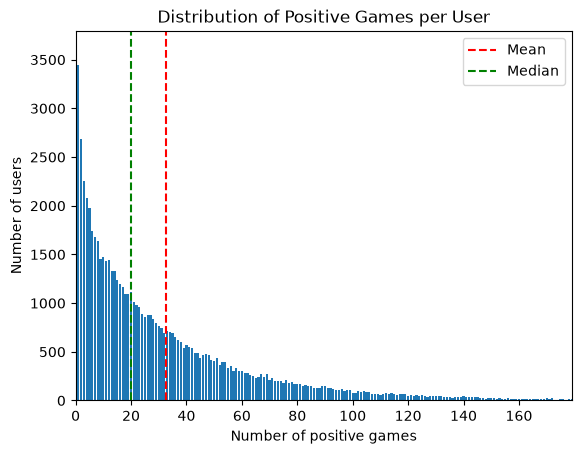

In [16]:
frequency = user_stats["positive_games"].value_counts().sort_index()
plt.bar(frequency.index, frequency.values)
plt.xlim(0, user_stats["positive_games"].quantile(0.99))
plt.axvline(x=user_stats["positive_games"].mean(), color="red", linestyle="--", label="Mean")
plt.axvline(
    x=user_stats["positive_games"].median(),
    color="green",
    linestyle="--",
    label="Median"
)
plt.xlabel("Number of positive games")
plt.ylabel("Number of users")
plt.title("Distribution of Positive Games per User")
plt.legend()
plt.show()

In [18]:
thresholds = [1, 2, 5, 10, 20]
threshold_results = []

for i in thresholds:
    new = user_stats[user_stats["positive_games"] >= i]

    retained_users = len(new)
    retained_interactions = new["positive_games"].sum()

    validation = {
        "threshold": i,
        "retained_users": retained_users,
        "perc_retained_users": retained_users / unique_users * 100,
        "retained_interactions": retained_interactions,
        "perc_retained_interactions": retained_interactions / positive_interactions * 100
    }

    threshold_results.append(validation)

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(2)

,threshold,retained_users,perc_retained_users,retained_interactions,perc_retained_interactions
0,1,67297,94.90,2300869,100.00
1,2,63853,90.05,2297425,99.85
2,5,56834,80.15,2276983,98.96
3,10,48337,68.16,2218661,96.43
4,20,35545,50.13,2037015,88.53


In [20]:
query = f"""
    SELECT
        game_id,
        COUNT(*) AS total_interactions,
        COUNTIF(positive_60m) AS positive_interactions
    FROM `{table_id}`
    GROUP BY game_id
"""

game_stats = client.query(query).result().to_dataframe(
    create_bqstorage_client=False
)

game_stats[["total_interactions", "positive_interactions"]].describe(
    percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

,total_interactions,positive_interactions
count,10978.0,10978.0
mean,464.026416,209.589087
std,1793.593696,1179.988259
min,1.0,0.0
1%,1.0,0.0
5%,1.0,0.0
10%,2.0,0.0
25%,9.0,1.0
50%,43.0,9.0
75%,220.0,50.0


In [21]:
game_popularity = game_stats["positive_interactions"].sort_values(
    ascending=False
).reset_index(drop=True)

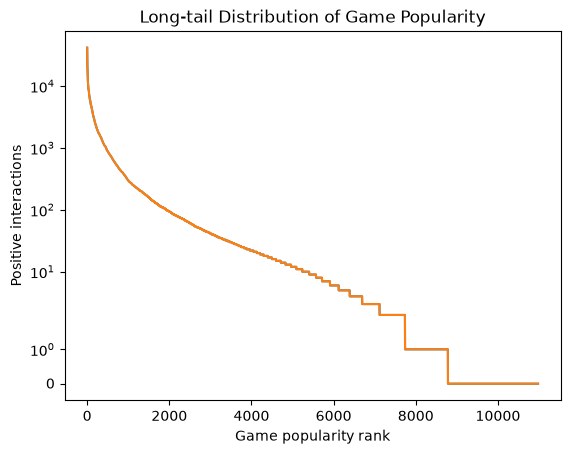

In [25]:
plt.plot(game_popularity)
plt.plot(game_popularity)
plt.xlabel("Game popularity rank")
plt.ylabel("Positive interactions")
plt.title("Long-tail Distribution of Game Popularity")
plt.yscale("symlog")
plt.show()


In [28]:
top_percentages = [0.01, 0.05, 0.10]

for p in top_percentages:
    n_games = int(unique_games * p)

    top_interactions = game_popularity.head(n_games).sum()

    percentage = top_interactions / positive_interactions * 100

    print(f"Top {p:.0%} of games: {percentage:.2f}% of positive interactions")

Top 1% of games: 43.38% of positive interactions
Top 5% of games: 77.38% of positive interactions
Top 10% of games: 88.30% of positive interactions
